# Text-to-SQL: QLoRA-дообучение Qwen2.5-1.5B на бесплатной Colab T4


In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 1. Код и зависимости

In [2]:
REPO = "https://github.com/sofetizm/text2sql-lora.git"
!git clone -q $REPO
%cd text2sql-lora
!pip install -q -r requirements.txt && pip install -q -e .

fatal: destination path 'text2sql-lora' already exists and is not an empty directory.
/content/text2sql-lora
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for t2s (pyproject.toml) ... done


In [3]:
from google.colab import drive
drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/text2sql-lora'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Данные

In [4]:
!python -m t2s.data --out data
!python -m t2s.benchmark_db --out benchmark/dbs

{
  "raw": 78577,
  "dropped_duplicates": 1,
  "dropped_too_long": 0,
  "dropped_invalid_sql": 1677,
  "clean": 76899,
  "n_test": 1000,
  "n_val": 500,
  "n_train": 15000
}
shop: benchmark/dbs/shop.sqlite
university: benchmark/dbs/university.sqlite
library: benchmark/dbs/library.sqlite


## 3. Базовая модель (до обучения)
Обе модели оцениваются в одинаковой 4-битной квантизации

In [5]:
!python -m t2s.evaluate --name base --backend hf --model Qwen/Qwen2.5-1.5B-Instruct --load-in-4bit

Loading weights: 100% 338/338 [00:01<00:00, 278.48it/s]
Оцениваю 'base' на 420 заданиях…
  24/420  accuracy so far: 75.0%
  40/420  accuracy so far: 65.0%
  64/420  accuracy so far: 67.2%
  80/420  accuracy so far: 63.8%
  104/420  accuracy so far: 66.3%
  120/420  accuracy so far: 65.0%
  144/420  accuracy so far: 63.9%
  160/420  accuracy so far: 60.6%
  184/420  accuracy so far: 57.6%
  200/420  accuracy so far: 58.0%
  224/420  accuracy so far: 57.6%
  240/420  accuracy so far: 57.5%
  264/420  accuracy so far: 59.1%
  280/420  accuracy so far: 58.9%
  304/420  accuracy so far: 57.9%
  320/420  accuracy so far: 58.4%
  344/420  accuracy so far: 58.4%
  360/420  accuracy so far: 58.1%
  384/420  accuracy so far: 57.8%
  400/420  accuracy so far: 58.0%
  420/420  accuracy so far: 57.9%
{
  "custom": {
    "n": 120,
    "accuracy": 65.0,
    "executable": 79.2,
    "by_lang": {
      "en": 71.7,
      "ru": 58.3
    },
    "by_difficulty": {
      "easy": 81.0,
      "hard": 47.1,
   

## 4. Обучение

In [6]:
!python -m t2s.train --config configs/qlora_qwen1.5b.yaml

train: 15000 примеров (пропущено длинных: 0)
Loading weights: 100% 338/338 [00:01<00:00, 274.41it/s]
обучаемых параметров: 18,464,768 из 1,562,179,072 (1.18%)
[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 151643}.
  0% 0/938 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
{'loss': '0.1191', 'grad_norm': '0.5658', 'learning_rate': '

## 5. Дообученная модель

In [7]:
!python -m t2s.evaluate --name lora --backend hf --model Qwen/Qwen2.5-1.5B-Instruct \
    --adapter outputs/qwen1.5b-sql-lora/adapter --load-in-4bit

Loading weights: 100% 338/338 [00:01<00:00, 262.98it/s]
Оцениваю 'lora' на 420 заданиях…
  24/420  accuracy so far: 16.7%
  40/420  accuracy so far: 20.0%
  64/420  accuracy so far: 31.2%
  80/420  accuracy so far: 36.2%
  104/420  accuracy so far: 38.5%
  120/420  accuracy so far: 37.5%
  144/420  accuracy so far: 43.8%
  160/420  accuracy so far: 47.5%
  184/420  accuracy so far: 51.1%
  200/420  accuracy so far: 52.5%
  224/420  accuracy so far: 56.7%
  240/420  accuracy so far: 59.2%
  264/420  accuracy so far: 61.7%
  280/420  accuracy so far: 62.9%
  304/420  accuracy so far: 63.5%
  320/420  accuracy so far: 65.0%
  344/420  accuracy so far: 66.0%
  360/420  accuracy so far: 66.7%
  384/420  accuracy so far: 67.4%
  400/420  accuracy so far: 67.5%
  420/420  accuracy so far: 67.6%
{
  "custom": {
    "n": 120,
    "accuracy": 37.5,
    "executable": 68.3,
    "by_lang": {
      "en": 45.0,
      "ru": 30.0
    },
    "by_difficulty": {
      "easy": 31.0,
      "hard": 38.2,
   

## 6. API-модель для сравнения

In [14]:
!git pull -q
import os
from google.colab import userdata
os.environ['OPENAI_API_KEY'] = userdata.get('GROQ_API_KEY')
os.environ['OPENAI_BASE_URL'] = 'https://api.groq.com/openai/v1'

!python -m t2s.evaluate --name gpt-oss-120b --backend openai --model openai/gpt-oss-120b \
    --suites custom --reasoning-effort low --max-new-tokens 2048 --rpm 10 \
    --price-in 0.15 --price-out 0.60

Оцениваю 'gpt-oss-120b' на 120 заданиях…
  20/120  accuracy so far: 100.0%
  40/120  accuracy so far: 100.0%
  60/120  accuracy so far: 98.3%
  80/120  accuracy so far: 96.2%
  100/120  accuracy so far: 97.0%
  120/120  accuracy so far: 97.5%
{
  "custom": {
    "n": 120,
    "accuracy": 97.5,
    "executable": 99.2,
    "by_lang": {
      "en": 96.7,
      "ru": 98.3
    },
    "by_difficulty": {
      "easy": 100.0,
      "hard": 97.1,
      "medium": 95.5
    },
    "by_db": {
      "library": 100.0,
      "shop": 100.0,
      "university": 92.5
    },
    "errors": {
      "wrong_result": 2,
      "syntax_error": 1
    }
  },
  "speed": {
    "latency_mean_s": 0.372,
    "latency_p95_s": 0.544,
    "output_tokens_per_s": 162.3
  },
  "cost": {
    "total_usd": 0.0103,
    "per_1000_queries_usd": 0.0857
  }
}
Результаты: results/gpt-oss-120b.json


## 7. Итоги

# Результаты

| Модель | Свой бенчмарк, RU | Свой бенчмарк, EN | Easy | Medium | Hard | Held-out EM | Held-out выполнимо | Задержка, с | Токенов/с | $ / 1000 запросов |
|---|---|---|---|---|---|---|---|---|---|---|
| **base** | 58.3 | 71.7 | 81.0 | 63.6 | 47.1 | 55.0 | 96.7 | 0.939 | 35.1 | 0.0 |
| **gpt-oss-120b** | 98.3 | 96.7 | 100.0 | 95.5 | 97.1 | — | — | 0.372 | 162.3 | 0.0857 |
| **lora** | 30.0 | 45.0 | 31.0 | 43.2 | 38.2 | 79.7 | 99.3 | 0.928 | 31.6 | 0.0 |

## Типы ошибок на своём бенчмарке

| Модель | несуществующие таблицы/столбцы | синтаксис | выполнился, но ответ неверный |
|---|---|---|---|
| **base** | 19 | 6 | 17 |
| **gpt-oss-120b** | 0 | 1 | 2 |
| **lora** | 35 | 3 | 37 |

![accuracy](accuracy.png)

{'total': 120, 'fixed': 6, 'broken': 39, 'both_wrong': 36}
Отчёт: results/compare_base_vs_lora.md


# Результаты

| Модель | Свой бенчмарк, RU | Свой бенчмарк, EN | Easy | Medium | Hard | Held-out EM | Held-out выполнимо | Задержка, с | Токенов/с | $ / 1000 запросов |
|---|---|---|---|---|---|---|---|---|---|---|
| **base** | 58.3 | 71.7 | 81.0 | 63.6 | 47.1 | 55.0 | 96.7 | 0.939 | 35.1 | 0.0 |
| **gpt-oss-120b** | 98.3 | 96.7 | 100.0 | 95.5 | 97.1 | — | — | 0.372 | 162.3 | 0.0857 |
| **lora** | 30.0 | 45.0 | 31.0 | 43.2 | 38.2 | 79.7 | 99.3 | 0.928 | 31.6 | 0.0 |

## Типы ошибок на своём бенчмарке

| Модель | несуществующие таблицы/столбцы | синтаксис | выполнился, но ответ неверный |
|---|---|---|---|
| **base** | 19 | 6 | 17 |
| **gpt-oss-120b** | 0 | 1 | 2 |
| **lora** | 35 | 3 | 37 |




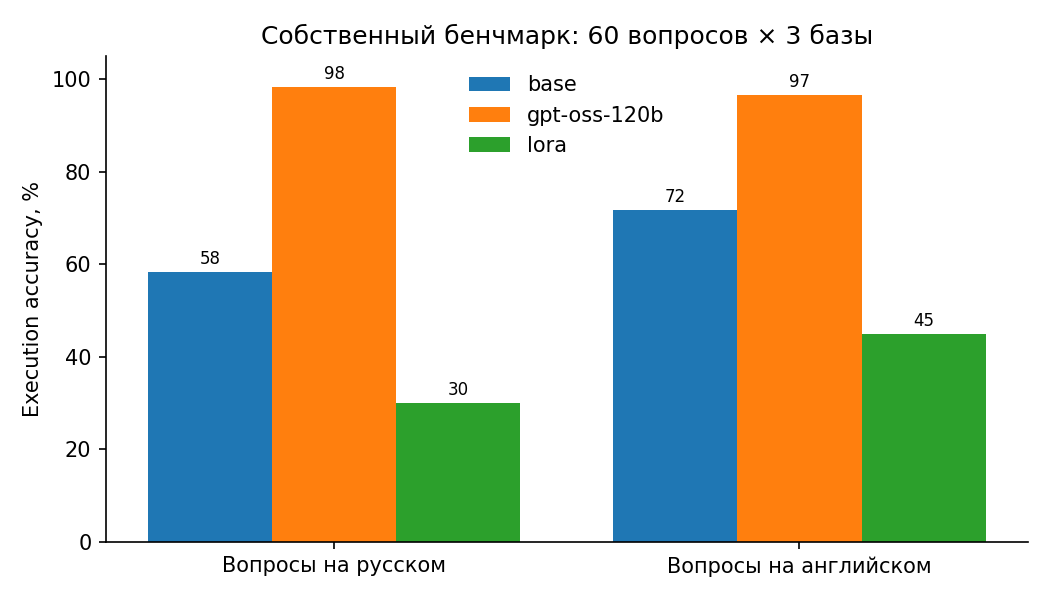

In [15]:
!python -m t2s.report --results results
!python -m t2s.compare results/base_predictions.jsonl results/lora_predictions.jsonl

from IPython.display import Markdown, Image, display
display(Markdown(open('results/RESULTS.md').read().replace('![accuracy](accuracy.png)', '')))
display(Image('results/accuracy.png'))

## 8. Сохранение

In [16]:
!mkdir -p "$SAVE_DIR" && cp -r results outputs/qwen1.5b-sql-lora/adapter outputs/qwen1.5b-sql-lora/train_meta.json "$SAVE_DIR"/
!cd results && zip -qr ../results.zip . && cd ..
from google.colab import files
files.download('results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Адаптер на Hugging Face Hub

In [19]:
from huggingface_hub import create_repo, login, upload_folder
login()
HF_REPO = 'Sofetizm/qwen1.5b-text2sql-lora'
create_repo(HF_REPO, exist_ok=True)
upload_folder(repo_id=HF_REPO, folder_path='outputs/qwen1.5b-sql-lora/adapter')

CommitInfo(commit_url='https://huggingface.co/Sofetizm/qwen1.5b-text2sql-lora/commit/6f808e474bfdc6a41953fc0ae9a773e34933520c', commit_message='Upload folder using huggingface_hub', commit_description='', oid='6f808e474bfdc6a41953fc0ae9a773e34933520c', pr_url=None, repo_url=RepoUrl('https://huggingface.co/Sofetizm/qwen1.5b-text2sql-lora', endpoint='https://huggingface.co', repo_type='model', repo_id='Sofetizm/qwen1.5b-text2sql-lora'), pr_revision=None, pr_num=None)